In [37]:
import pypsa
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
%matplotlib inline

from synthseer import *
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [38]:
input_data = synth_data(2025, nyears=3, load_growth=0.2, excess_cap=1)

In [39]:
model = create_model_from_data(input_data, voll=5000)

In [40]:
minpu, maxpu = model.components.Generator.get_bounds_pu()

In [41]:
model.components.Load

'Load' Components
-----------------
Attached to PyPSA Network 'Unnamed Network'
Components: 1

In [42]:
model.optimize()

INFO:linopy.model: Solve problem using Highs solver
INFO:linopy.io:Writing objective.
Writing continuous variables.: 100%|██████████████| 2/2 [00:00<00:00,  2.62it/s]
INFO:linopy.io: Writing time: 5.8s


Running HiGHS 1.12.0 (git hash: n/a): Copyright (c) 2025 HiGHS under MIT licence terms
LP linopy-problem-9yxqhoqq has 867255 rows; 420495 cols; 1498515 nonzeros
Coefficient ranges:
  Matrix  [2e-04, 1e+00]
  Cost    [5e+00, 5e+05]
  Bound   [0e+00, 0e+00]
  RHS     [3e-02, 2e+03]
Presolving model
247463 rows, 355129 cols, 797480 nonzeros  0s
Dependent equations search running on 26280 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.01s (limit = 1000.00s)
247463 rows, 341719 cols, 784070 nonzeros  2s
Presolve reductions: rows 247463(-619792); columns 341719(-78776); nonzeros 784070(-714445) 
Solving the presolved LP
Using EKK dual simplex solver - serial
  Iteration        Objective     Infeasibilities num(sum)
          0     0.0000000000e+00 Pr: 26280(1.50447e+07) 3s
     110496     1.0750139038e+09 Pr: 44199(9.67328e+06) 8s
     122683     1.1791158228e+09 Pr: 44046(9.12846e+06) 13s
     129868     1.2419425665e+09 Pr: 36802(1.77167

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 420495 primals, 867255 duals
Objective: 1.39e+09
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Generator-ext-p-lower, Generator-ext-p-upper were not assigned to the network.


('ok', 'optimal')

/Users/mohini/Documents/repos/rhiza/seer/synthseer.py:288: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



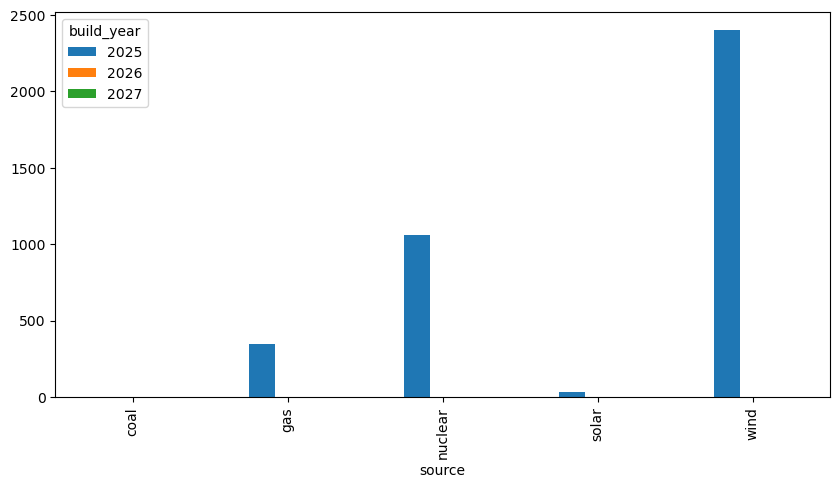

In [43]:
viz_model(model)

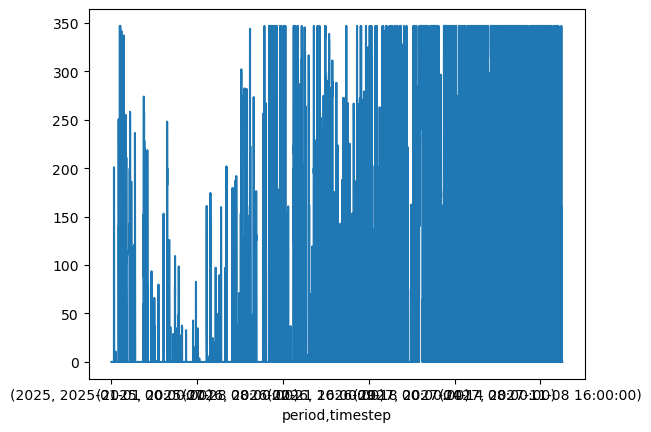

In [48]:
model.generators_t.p["gas - 0_2025"].plot()
plt.show()

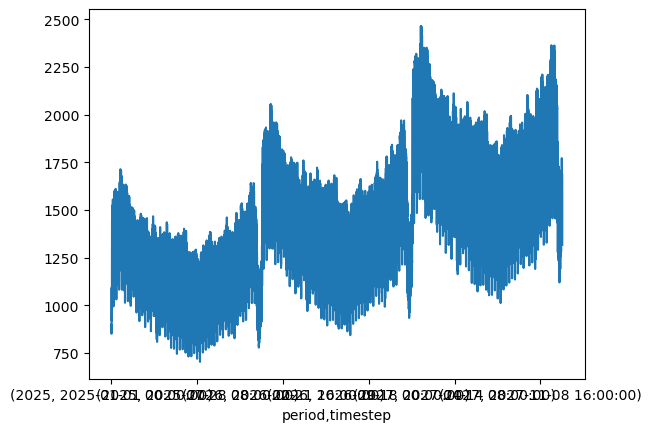

In [46]:
model.loads_t.p["load - 0"].plot()
plt.show()